# Studio intra-layer sulla rete completa

**Come sono organizzati gli indirizzi in ciascun mercato?** Username e numeri sono analizzati separatamente: due grafi, nessun confronto tra i layer.

La rete è quella `completa` della fase B: le regole del grafo applicate alle righe così come sono (NULL → A crea il nodo, A → B crea l'arco, B → B niente).
**Non c'è nessuna distinzione tra wallet e smart contract**: ogni indirizzo che compare come mittente o destinatario è un nodo, compresi i contratti di vendita, di noleggio e i vault dei prestiti. L'elenco dei contratti identificati non è usato in nessun punto.

Blocchi: struttura, hub, comunità, categorie, profili. Le comunità usano Leiden fino a convergenza (`n_iterations=-1`). Richiede le tabelle di `fase_b_reti.ipynb`; non modifica i file delle altre fasi.

## 0. Dati

In [1]:
import random
import numpy as np
import pandas as pd
import scipy.sparse as sp
import igraph as ig
import leidenalg as la
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score
from analisi_utils import *

stile()
RETE = 'completa'          # ogni indirizzo è un nodo: nessuna distinzione tra wallet e contratti
P = 'c_completa_'          # prefisso di figure e tabelle di questo notebook
TOP_COMUNITA = 12          # comunità mostrate nelle heatmap e nei profili
MIN_NFT_CAT = 200          # una categoria entra nella heatmap se ha almeno questi NFT nel layer

G = carica_grafi(RETE)
leggibile(pd.DataFrame({NOME[l]: {'indirizzi (nodi)': g.vcount(), 'archi (coppie)': g.ecount(), 'passaggi': int(sum(g.es['weight']))}
                        for l, g in G.items()}))

,Username,Numeri
indirizzi (nodi),554.965,149.031
archi (coppie),1.148.787,339.635
passaggi,1.923.120,656.071


## 1. Struttura

Metriche sugli indirizzi con almeno un arco, per ogni layer.
* **Densità**: archi presenti / archi possibili.
* **Reciprocità**: quota di archi A → B per cui esiste anche B → A.
* **Clustering medio**: per ogni nodo, quota delle coppie di suoi vicini collegate tra loro, poi media; **transitività globale**: la stessa quota calcolata su tutta la rete.
* **Centralizzazione di Freeman**: 0 se tutti hanno lo stesso numero di contatti, 1 se la rete è una stella.
* **Gini** e **quota del top 1% / 10%**: quanto i passaggi sono concentrati su pochi indirizzi.
* **Peso degli archi**: passaggi tra la stessa coppia ordinata di indirizzi.

In [2]:
def centralizzazione(u):
    k = np.array(u.degree())
    n = len(k)
    return (k.max() - k).sum() / ((n - 1) * (n - 2))

def struttura(g):
    h = attivi(g)
    u = non_orientato(h)
    s = np.array(h.strength(mode='all', weights='weight'), dtype=float)
    w = np.array(g.es['weight'])
    ordinati = np.sort(s)
    comp = np.array(g.connected_components('weak').sizes())
    comp_attivi = comp[comp > 1]
    return {
        'indirizzi (nodi)': g.vcount(), 'indirizzi con archi': h.vcount(), 'archi (coppie)': g.ecount(), 'passaggi': int(w.sum()),
        'componenti (senza isolati)': len(comp_attivi), 'componente gigante (% indirizzi con archi)': comp_attivi.max() / h.vcount(),
        'densità': h.density(), 'reciprocità': h.reciprocity(), 'clustering medio': u.transitivity_avglocal_undirected(mode='zero'),
        'transitività globale': u.transitivity_undirected(), 'grado medio (in + out)': np.mean(h.degree()),
        'grado massimo': max(h.degree()), 'forza massima': int(s.max()), 'centralizzazione di Freeman': centralizzazione(u),
        'Gini della forza': gini(s), 'quota passaggi del top 1%': ordinati[-max(1, len(s) // 100):].sum() / s.sum(),
        'quota passaggi del top 10%': ordinati[-max(1, len(s) // 10):].sum() / s.sum(),
        'archi con più passaggi (%)': (w > 1).mean(), 'passaggi su archi ripetuti (%)': w[w > 1].sum() / w.sum(), 'peso massimo': int(w.max()),
    }

STRUTTURA = pd.DataFrame({NOME[l]: struttura(g) for l, g in G.items()})
salva_tabella(STRUTTURA, P + 'struttura')
leggibile(STRUTTURA)

,Username,Numeri
indirizzi (nodi),554.965,149.031
indirizzi con archi,525.505,140.115
archi (coppie),1.148.787,339.635
passaggi,1.923.120,656.071
componenti (senza isolati),8.314,1.200
componente gigante (% indirizzi con archi),0.954,0.979
densità,4.16e-06,1.73e-05
reciprocità,0.416,0.177
clustering medio,0.0846,0.164
transitività globale,0.00148,0.00661


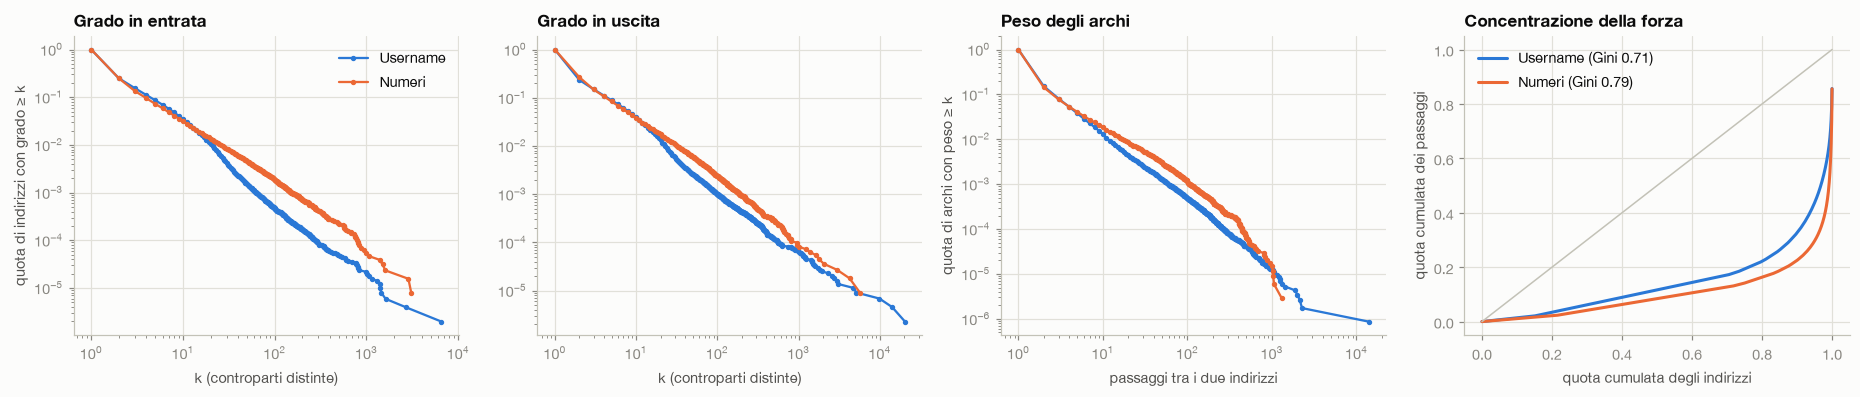

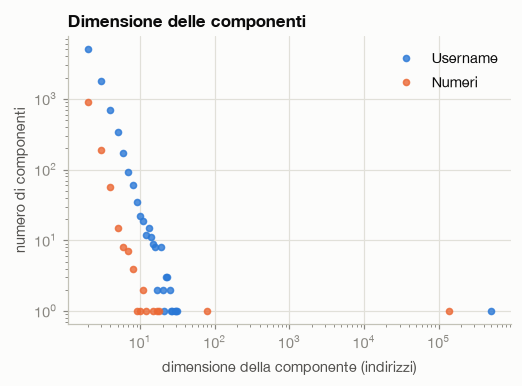

In [3]:
fig, axes = plt.subplots(1, 4, figsize=(17, 3.7))
for ax, (titolo, modo) in zip(axes, [('Grado in entrata', 'in'), ('Grado in uscita', 'out')]):
    for l, g in G.items():
        k = np.array(g.degree(mode=modo))
        kk, pp = ccdf(k[k > 0])
        ax.loglog(kk, pp, color=COLORI[l], label=NOME[l], marker='o', markersize=2.5, linewidth=1.5)
    ax.set_title(titolo)
    ax.set_xlabel('k (controparti distinte)')
axes[0].set_ylabel('quota di indirizzi con grado ≥ k')
axes[0].legend()
for l, g in G.items():
    kk, pp = ccdf(g.es['weight'])
    axes[2].loglog(kk, pp, color=COLORI[l], label=NOME[l], marker='o', markersize=2.5, linewidth=1.5)
axes[2].set_title('Peso degli archi')
axes[2].set_xlabel('passaggi tra i due indirizzi')
axes[2].set_ylabel('quota di archi con peso ≥ k')
for l, g in G.items():
    x = np.sort(np.array(attivi(g).strength(mode='all', weights='weight'), dtype=float))
    c = np.r_[0, np.cumsum(x) / x.sum()]
    q = np.linspace(0, 1, len(c))
    passo = max(1, len(c) // 2000)
    axes[3].plot(q[::passo], c[::passo], color=COLORI[l], label=f'{NOME[l]} (Gini {gini(x):.2f})')
axes[3].plot([0, 1], [0, 1], color='#c3c2b7', linewidth=1)
axes[3].set_title('Concentrazione della forza')
axes[3].set_xlabel('quota cumulata degli indirizzi')
axes[3].set_ylabel('quota cumulata dei passaggi')
axes[3].legend(loc='upper left')
fig.tight_layout()
salva_figura(fig, P + 'gradi_e_concentrazione')
plt.show()

fig, ax = plt.subplots(figsize=(5.2, 3.4))
for l, g in G.items():
    dim = np.array(g.connected_components('weak').sizes())
    dim = dim[dim > 1]
    kk, conte = np.unique(dim, return_counts=True)
    ax.loglog(kk, conte, color=COLORI[l], label=NOME[l], linestyle='', marker='o', markersize=4, alpha=0.8)
ax.set_xlabel('dimensione della componente (indirizzi)')
ax.set_ylabel('numero di componenti')
ax.set_title('Dimensione delle componenti')
ax.legend()
salva_figura(fig, P + 'componenti')
plt.show()

## 2. Hub

Classifiche per grado in entrata, grado in uscita, grado, forza e PageRank (con e senza pesi). Come nella fase C la soglia è sul grado: un hub ha almeno 100 archi, e per ogni metrica si prendono tanti indirizzi quanti sono quelli con grado ≥ 100. Il Jaccard misura quanti coincidono tra due metriche: 1 = stessi indirizzi, 0 = nessuno in comune. Gli indirizzi sono abbreviati: nel report non vanno nomi di wallet.

indirizzi con grado ≥ 100 {'Username': 945, 'Numeri': 592}


grado_in  grado_out     forza  pagerank
layer    indirizzo                                           
Username 0:53191a57…       818      20429  4.39e+04  0.008966
         0:cf01d60c…      6572      14184 5.165e+04  0.005203
         0:ee007f6b…       247       9909 1.982e+04  0.004208
         0:ef90ee35…      2691        506      7448  0.002016
         0:6c9adfdd…      1414       2328 1.015e+04  0.001795
         0:136320fc…      1619         34      5448  0.001621
         0:fb33b0c2…      1400         21      5171  0.001378
         0:a4793bce…       240       2943      5887  0.001307
         0:d83bce88…       368       1567      8119  0.001246
         0:a533ba10…       998          5      4076  0.001235
Numeri   0:a4793bce…       482       5726 1.146e+04   0.01145
         0:3d8c8790…      3090       2050 1.316e+04   0.01004
         0:53191a57…       252       4251      8516  0.009178
         0:9a7752ca…      2869       2985      7565  0.008225
         0:3142088f…      1500       1241 1.039e+04   0.00547
         0:e1a063d2…       986         12      2508  0.003591
         0:78a671e0…      1057         36      2628   0.00342
         0:51821d28…       305       1652      3304  0.003169
         0:b6e179b3…       801        956      2018  0.002942
         0:09fe8bad…      1392       1384      6540   0.00268

,top 1% per grado: quota degli archi toccati,indirizzi con grado ≥ 100,Jaccard minimo tra metriche,Jaccard massimo tra metriche,Jaccard PageRank con / senza pesi,Spearman PageRank con / senza pesi
layer,,,,,,
Username,0.2486,945,0.1842,0.7813,0.7813,0.9294
Numeri,0.3569,592,0.2898,0.6653,0.5538,0.9103


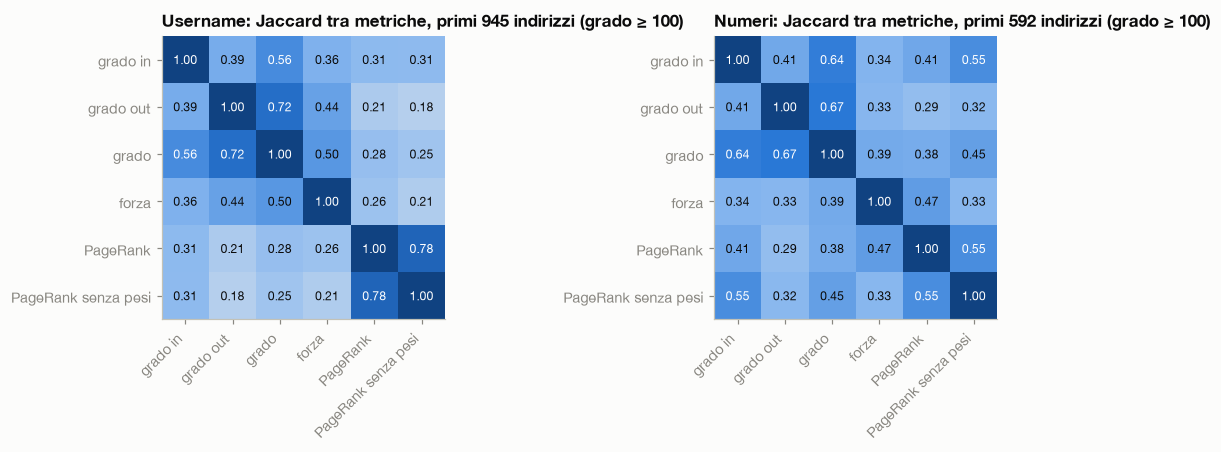

In [4]:
def centralita(g):
    return pd.DataFrame({'indirizzo': g.vs['name'], 'layer': g['layer'], 'grado_in': g.degree(mode='in'), 'grado_out': g.degree(mode='out'),
                         'grado': g.degree(mode='all'), 'forza_in': g.strength(mode='in', weights='weight'),
                         'forza_out': g.strength(mode='out', weights='weight'), 'forza': g.strength(mode='all', weights='weight'),
                         'pagerank': g.pagerank(weights='weight'), 'pagerank_senza_pesi': g.pagerank()})

CENTR = {l: centralita(g) for l, g in G.items()}
METRICHE = ['grado_in', 'grado_out', 'grado', 'forza', 'pagerank', 'pagerank_senza_pesi']
NOMI_M = {'grado_in': 'grado in', 'grado_out': 'grado out', 'grado': 'grado', 'forza': 'forza', 'pagerank': 'PageRank', 'pagerank_senza_pesi': 'PageRank senza pesi'}
GRADO_HUB = 100
K_HUB = {l: int((CENTR[l].grado >= GRADO_HUB).sum()) for l in LAYERS}
print('indirizzi con grado ≥', GRADO_HUB, {NOME[l]: k for l, k in K_HUB.items()})
top = lambda df, m, k: set(df.nlargest(k, m).indirizzo)
jaccard = lambda a, b: len(a & b) / len(a | b)

righe = []
for l in LAYERS:
    r = CENTR[l].nlargest(10, 'pagerank')
    righe.append(r.assign(layer=NOME[l], indirizzo=r.indirizzo.map(corto))[['layer', 'indirizzo', 'grado_in', 'grado_out', 'forza', 'pagerank']])
display(pd.concat(righe).set_index(['layer', 'indirizzo']))
pd.concat([CENTR[l].nlargest(100, m).assign(metrica=m, indirizzo=lambda d: d.indirizzo.map(corto))[['layer', 'metrica', 'indirizzo', m]].rename(columns={m: 'valore'})
           for l in LAYERS for m in METRICHE]).to_csv(TABELLE / f'{P}hub_top100.csv', index=False)

righe = []
for l in LAYERS:
    c = CENTR[l]
    kk = K_HUB[l]
    k = np.array(G[l].degree())
    righe.append({'layer': NOME[l], 'top 1% per grado: quota degli archi toccati': np.sort(k)[-len(k) // 100:].sum() / k.sum(),
                  'indirizzi con grado ≥ 100': kk,
                  'Jaccard minimo tra metriche': min(jaccard(top(c, a, kk), top(c, b, kk)) for a in METRICHE for b in METRICHE if a < b),
                  'Jaccard massimo tra metriche': max(jaccard(top(c, a, kk), top(c, b, kk)) for a in METRICHE for b in METRICHE if a < b),
                  'Jaccard PageRank con / senza pesi': jaccard(top(c, 'pagerank', kk), top(c, 'pagerank_senza_pesi', kk)),
                  'Spearman PageRank con / senza pesi': c[['pagerank', 'pagerank_senza_pesi']].corr(method='spearman').iloc[0, 1]})
HUB = pd.DataFrame(righe).set_index('layer')
salva_tabella(HUB, P + 'hub_stabilita')
display(HUB)

fig, axes = plt.subplots(1, len(LAYERS), figsize=(5.2 * len(LAYERS), 4.2))
ramp = LinearSegmentedColormap.from_list('blu', ['#f0efec', '#86b6ef', '#2a78d6', '#104281'])
for ax, l in zip(axes, LAYERS):
    c = CENTR[l]
    mat = np.array([[jaccard(top(c, a, K_HUB[l]), top(c, b, K_HUB[l])) for b in METRICHE] for a in METRICHE])
    ax.imshow(mat, vmin=0, vmax=1, cmap=ramp)
    ax.set_xticks(range(len(METRICHE)), [NOMI_M[m] for m in METRICHE], rotation=45, ha='right')
    ax.set_yticks(range(len(METRICHE)), [NOMI_M[m] for m in METRICHE])
    ax.grid(False)
    for i in range(len(METRICHE)):
        for j in range(len(METRICHE)):
            ax.text(j, i, f'{mat[i, j]:.2f}', ha='center', va='center', fontsize=8, color='white' if mat[i, j] > 0.55 else INK)
    ax.set_title(f'{NOME[l]}: Jaccard tra metriche, primi {K_HUB[l]} indirizzi (grado ≥ {GRADO_HUB})')
fig.tight_layout()
salva_figura(fig, P + 'hub_jaccard_metriche')
plt.show()

## 3. Comunità

**Rappresentazione**: grafo non orientato degli indirizzi con archi, peso = passaggi tra i due indirizzi nelle due direzioni. Le comunità si estraggono dai soli collegamenti; categorie e prezzi entrano dopo, per interpretarle.

Riferimento: **Leiden con risoluzione 1, fino a convergenza**. La sensibilità confronta un altro seed, risoluzione 0,5 e 2 (con 10 iterazioni di Leiden, per tenere prevedibile il tempo di calcolo) e Louvain, misurando quanto ogni partizione somiglia a quella di riferimento (NMI e ARI: 1 = identica, 0 = non più simile di una partizione a caso).

In [5]:
def leiden(u, risoluzione=1.0, seed=SEED, iterazioni=-1):
    # -1 = fino a convergenza (riferimento); le varianti usano 10 iterazioni
    return np.array(la.find_partition(u, la.RBConfigurationVertexPartition, weights='weight', resolution_parameter=risoluzione,
                                      n_iterations=iterazioni, seed=seed).membership)

def per_dimensione(m):
    # rinumera le comunità: 0 è la più grande
    valori, inverso, conte = np.unique(m, return_inverse=True, return_counts=True)
    rango = np.argsort(np.argsort(-conte))
    return rango[inverso]

righe, PARTIZIONI = [], {}
for l, g in G.items():
    u = non_orientato(attivi(g))
    rif = per_dimensione(leiden(u))
    PARTIZIONI[l] = (u, rif)
    random.seed(SEED)
    prove = {'Leiden, risoluzione 1': rif, 'Leiden, altro seed': leiden(u, 1.0, SEED + 1, 10), 'Leiden, risoluzione 0,5': leiden(u, 0.5, iterazioni=10),
             'Leiden, risoluzione 2': leiden(u, 2.0, iterazioni=10), 'Louvain': np.array(u.community_multilevel(weights='weight').membership)}
    for nome, m in prove.items():
        dim = np.bincount(per_dimensione(m))
        righe.append({'layer': NOME[l], 'partizione': nome, 'comunità': len(dim), 'comunità con almeno 100 indirizzi': int((dim >= 100).sum()),
                      'modularità': u.modularity(m.tolist(), weights='weight'), 'più grande (% indirizzi)': dim[0] / dim.sum(),
                      'indirizzi nelle 10 più grandi': np.sort(dim)[::-1][:10].sum() / dim.sum(),
                      'NMI con il riferimento': normalized_mutual_info_score(rif, m), 'ARI con il riferimento': adjusted_rand_score(rif, m)})
SENS = pd.DataFrame(righe).set_index(['layer', 'partizione'])
salva_tabella(SENS, P + 'comunita_sensibilita')
leggibile(SENS)

comunità comunità con almeno 100 indirizzi modularità più grande (% indirizzi) indirizzi nelle 10 più grandi NMI con il riferimento ARI con il riferimento
layer    partizione                                                                                                                                                                        
Username Leiden, risoluzione 1     22.508                                75      0.841                   0.0871                         0.459                      1                      1
         Leiden, altro seed        19.325                                77      0.837                    0.106                         0.473                  0.898                   0.63
         Leiden, risoluzione 0,5   19.673                                41       0.82                    0.194                          0.61                  0.879                  0.532
         Leiden, risoluzione 2     21.046                               151      0.827                   0.0402                         0.314                  0.874                  0.507
         Louvain                   20.308                                89      0.833                    0.108                         0.496                  0.897                  0.694
Numeri   Leiden, risoluzione 1      1.649                                65      0.705                    0.171                         0.655                      1                      1
         Leiden, altro seed         1.622                                60      0.704                    0.164                         0.651                  0.772                  0.778
         Leiden, risoluzione 0,5    1.775                                33      0.677                    0.299                         0.895                  0.633                  0.447
         Leiden, risoluzione 2      1.488                               136      0.686                   0.0835                         0.356                  0.608                  0.399
         Louvain                    1.437                                61       0.69                    0.172                         0.672                   0.63                  0.579

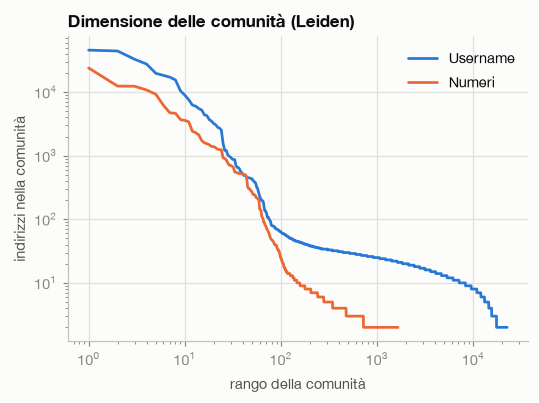

In [6]:
fig, ax = plt.subplots(figsize=(5.4, 3.6))
for l in LAYERS:
    dim = np.bincount(PARTIZIONI[l][1])
    ax.loglog(np.arange(1, len(dim) + 1), dim, color=COLORI[l], label=NOME[l], linewidth=1.8)
ax.set_xlabel('rango della comunità')
ax.set_ylabel('indirizzi nella comunità')
ax.set_title('Dimensione delle comunità (Leiden)')
ax.legend()
salva_figura(fig, P + 'comunita_dimensioni')
plt.show()

## 4. Categorie nelle comunità

Per ogni comunità si guarda quali NFT sono passati dai suoi indirizzi (un NFT conta se un indirizzo della comunità lo ha ceduto o ricevuto).
* **Multi-label**: un NFT con più categorie conta una volta per ogni categoria.
* **Arricchimento** = quota di NFT della comunità con quella categoria / quota negli NFT del layer con almeno un passaggio. La tabella riporta il log2: 0 = come nel resto del layer, +1 = il doppio, −1 = la metà. La heatmap non si ripete qui: le comunità sono quasi le stesse della rete senza contratti (`c_arricchimento_heatmap`), rinumerate perché i contratti formano una comunità in più.

In [7]:
cat_nft = pd.read_parquet(DATI / 'fragment_final.parquet', columns=['nft', 'layer', 'categories']).drop_duplicates('nft')
eventi = pd.read_parquet(cartella_variante(RETE) / 'transfer_events.parquet', columns=['layer', 'nft', 'src', 'dst', 'tipo_riga', 'ts', 'is_purchase', 'price_ton'])
passaggi = eventi[eventi.tipo_riga == 'A -> B'].reset_index(drop=True)
del eventi

def legami_comunita(layer):
    u, m = PARTIZIONI[layer]
    comunita = pd.Series(m, index=u.vs['name'])
    p = passaggi[passaggi.layer == layer]
    lunga = pd.concat([pd.DataFrame({'evento': p.index, 'nft': p.nft, 'comunita': p.src.map(comunita)}),
                       pd.DataFrame({'evento': p.index, 'nft': p.nft, 'comunita': p.dst.map(comunita)})]).dropna()
    return lunga.astype({'comunita': int}).drop_duplicates(['evento', 'comunita']), comunita

def arricchimento(layer):
    legami, _ = legami_comunita(layer)
    legami = legami[legami.comunita < TOP_COMUNITA]
    nft = pd.Index(passaggi.loc[passaggi.layer == layer, 'nft'].unique())
    c = cat_nft[cat_nft.layer == layer].set_index('nft').categories.reindex(nft)
    esplosa = c.explode()
    nomi_cat = sorted(esplosa.dropna().unique())
    i_cat = pd.Index(nomi_cat)
    C = sp.csr_matrix((np.ones(len(esplosa)), (nft.get_indexer(esplosa.index), i_cat.get_indexer(esplosa))), shape=(len(nft), len(nomi_cat)))
    distinti = legami.drop_duplicates(['comunita', 'nft'])
    B = sp.csr_matrix((np.ones(len(distinti)), (distinti.comunita, nft.get_indexer(distinti.nft))), shape=(TOP_COMUNITA, len(nft)))
    conta = (B @ C).toarray()
    n_c = np.asarray(B.sum(axis=1)).ravel()[:, None]
    quota_layer = np.asarray(C.sum(axis=0)).ravel() / len(nft)
    with np.errstate(divide='ignore', invalid='ignore'):
        lg = np.log2((conta / n_c) / quota_layer)
    r = pd.DataFrame({'layer': layer, 'comunita': np.repeat(np.arange(TOP_COMUNITA), len(nomi_cat)), 'categoria': nomi_cat * TOP_COMUNITA,
                      'nft_comunita': n_c.repeat(len(nomi_cat)).astype(int), 'nft_con_categoria': conta.ravel().astype(int),
                      'quota_nel_layer': np.tile(quota_layer, TOP_COMUNITA), 'log2_arricchimento': lg.ravel()})
    r['nft_categoria_layer'] = (r.quota_nel_layer * len(nft)).round().astype(int)
    return r

ENR = pd.concat([arricchimento(l) for l in LAYERS], ignore_index=True)
salva_tabella(ENR, P + 'arricchimento_categorie', index=False)

visibili = ENR[(ENR.nft_con_categoria >= 30) & (ENR.categoria != 'No_Categories')]
visibili.assign(layer=visibili.layer.map(NOME)).sort_values('log2_arricchimento', ascending=False).groupby('layer').head(10)[
    ['layer', 'comunita', 'categoria', 'nft_comunita', 'nft_con_categoria', 'quota_nel_layer', 'log2_arricchimento']]

,layer,comunita,categoria,nft_comunita,nft_con_categoria,quota_nel_layer,log2_arricchimento
441,Username,6,Legendary Pokemon,21262,35,8.963e-05,4.199
433,Username,6,Gen1 pokemon,21262,36,9.219e-05,4.199
459,Username,6,Top Verbs,21262,404,0.001188,3.999
446,Username,6,Mnemonic Club,21262,865,0.002566,3.987
458,Username,6,Top Nouns,21262,356,0.001063,3.978
429,Username,6,Food,21262,106,0.0003303,3.916
428,Username,6,Folklore,21262,43,0.0001511,3.743
440,Username,6,League of Legends Characters,21262,32,0.0001127,3.74
414,Username,6,Cartoon Characters,21262,34,0.000128,3.643
445,Username,6,Marvel Club,21262,149,0.0006018,3.542


## 5. Profili delle comunità

Per ognuna delle 12 comunità più grandi di ogni layer:
* **entropia delle categorie** (tra 0 e 1), su NFT distinti: 0 = una sola categoria, 1 = categorie equidistribuite;
* **prezzo mediano** delle vendite con prezzo a cui partecipa la comunità;
* **possesso mediano**, sui soli periodi conclusi (`COMPLETE`);
* **passaggi per indirizzo al mese** e **quota di vendite** sul totale dei passaggi;
* **peso del primo indirizzo**: quota dei passaggi della comunità che tocca il suo indirizzo più attivo. Se è alta, il profilo riflette soprattutto quell'indirizzo.

indirizzi  NFT distinti  passaggi categoria più frequente  entropia categorie  prezzo mediano (TON)  possesso mediano (giorni)  passaggi per indirizzo al mese  quota vendite  \
layer    comunita                                                                                                                                                                                  
Username C0            45792         84392    284562               5 Letters              0.4938                     6                      1.449                          0.1334         0.4767   
         C1            44392         21296    168876               5 Letters              0.5291                     6                     0.1104                         0.08136        0.06157   
         C2            32979         35762    189586           No_Categories              0.5659                     6                      2.867                           0.122         0.1411   
         C3            27679         64654    141062               5 Letters              0.5001                     7                      11.09                          0.1079         0.5869   
         C4            19767         20305     71596               7 Letters              0.5583                     7                      5.998                         0.08402        0.03138   
         C5            18372         19680    133772               5 Letters              0.3572                     8                      3.804                          0.1552        0.05601   
         C6            17213         21262     75843               6 Letters              0.6113                    43                      14.75                         0.09347         0.1296   
         C7            15548         36109    112989               5 Letters              0.4867                     8                      6.955                          0.1551         0.1319   
         C8            10519         23948     46674               5 Letters              0.5915                     7                      7.304                         0.09595         0.4425   
         C9             8977          8754     44188           No_Categories              0.6758                     6                      6.725                          0.1045        0.06635   
         C10            7583         12269     41022           No_Categories              0.6101                   5.9                      2.834                          0.1158         0.4392   
         C11            6266          4934     20835           No_Categories              0.5676                  9.06                      3.791                         0.07042         0.1505   
Numeri   C0            24028         57116    130959           No_Categories               0.409                    59                       34.7                          0.1172          0.829   
         C1            12448         19912     71297           No_Categories              0.3993                 854.9                      0.727                          0.1232         0.4995   
         C2            12384          7022     44813           No_Categories              0.4686                 231.5                     0.8971                         0.07783         0.2195   
         C3            10821          4700     30109           No_Categories              0.4142                   252                     0.6742                         0.05985         0.1682   
         C4             9257         19446     52942           No_Categories               0.444                   199                       8.49                           0.123         0.6104   
         C5             6204         18128     89168           No_Categories              0.4554                   857                      1.785                          0.3091         0.1253   
         C6             4726         10426     23374           No_Categories              0.3483   

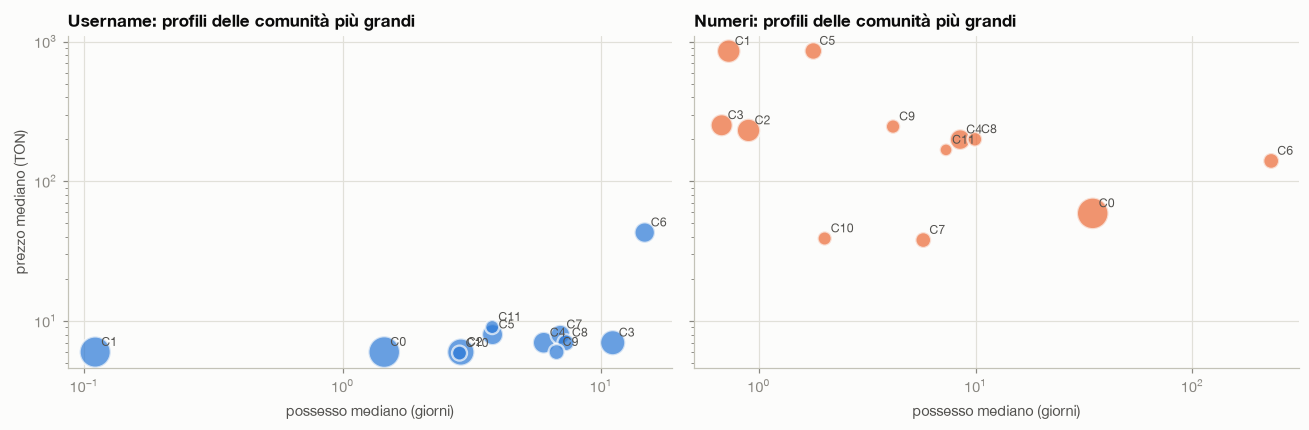

In [8]:
possessi = pd.read_parquet(cartella_variante(RETE) / 'holding_periods.parquet', columns=['layer', 'wallet', 'nft', 'status', 'holding_days'])
righe = []
for l in LAYERS:
    legami, comunita = legami_comunita(l)
    c = cat_nft[cat_nft.layer == l].set_index('nft').categories
    dim = comunita.value_counts()
    poss = possessi[(possessi.layer == l) & (possessi.status == 'COMPLETE')]
    poss = poss.assign(comunita=poss.wallet.map(comunita)).dropna(subset='comunita')
    d_med = poss.groupby('comunita').holding_days.median()
    for i in range(TOP_COMUNITA):
        ev = passaggi.loc[legami.loc[legami.comunita == i, 'evento']]
        membri = comunita.index[comunita == i]
        primo = pd.concat([ev.src[ev.src.isin(membri)], ev.dst[ev.dst.isin(membri)]]).value_counts().index[0]
        quota_primo = ((ev.src == primo) | (ev.dst == primo)).mean()
        nft = ev.nft.unique()
        frequenze = c.reindex(nft).explode().value_counts()
        q = frequenze / frequenze.sum()
        mesi = max(1.0, (ev.ts.max() - ev.ts.min()).total_seconds() / (86400 * 30.44))
        righe.append({'layer': NOME[l], 'comunita': f'C{i}', 'indirizzi': int(dim[i]), 'NFT distinti': len(nft), 'passaggi': len(ev),
                      'categoria più frequente': frequenze.index[0],
                      'entropia categorie': -(q * np.log(q)).sum() / np.log(len(q)) if len(q) > 1 else 0.0,
                      'prezzo mediano (TON)': ev.price_ton.median(), 'possesso mediano (giorni)': d_med.get(i, np.nan),
                      'passaggi per indirizzo al mese': len(ev) / dim[i] / mesi, 'quota vendite': ev.is_purchase.mean(),
                      'peso del primo indirizzo': quota_primo, 'mesi osservati': mesi})
PROFILI = pd.DataFrame(righe).set_index(['layer', 'comunita'])
salva_tabella(PROFILI, P + 'profili_comunita')
display(PROFILI)

fig, axes = plt.subplots(1, len(LAYERS), figsize=(6 * len(LAYERS), 4), sharey=True)
for ax, l in zip(axes, LAYERS):
    r = PROFILI.loc[NOME[l]]
    ax.scatter(r['possesso mediano (giorni)'], r['prezzo mediano (TON)'], s=30 + 400 * r['indirizzi'] / r['indirizzi'].max(), color=COLORI[l], alpha=0.7,
               edgecolors=SUPERFICIE, linewidths=1.5)
    for nome, x in r.iterrows():
        ax.annotate(nome, (x['possesso mediano (giorni)'], x['prezzo mediano (TON)']), fontsize=8, color=SECONDARIO, xytext=(4, 4), textcoords='offset points')
    ax.set_xscale('symlog', linthresh=0.1); ax.set_yscale('log')
    ax.set_xlabel('possesso mediano (giorni)')
    ax.set_title(f'{NOME[l]}: profili delle comunità più grandi')
axes[0].set_ylabel('prezzo mediano (TON)')
fig.tight_layout()
salva_figura(fig, P + 'profili_comunita')
plt.show()